<a href="https://colab.research.google.com/github/BagusWichaksono/PCVK_Ganjil_2026/blob/main/Modul7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL P7 - SEGMENTASI CITRA DENGAN THRESHOLDING
**Mata Kuliah:** Pengolahan Citra dan Visi Komputer  
**Jurusan:** Teknologi Informasi - Politeknik Negeri Malang  
**Repository / Notebook:** Week7.ipynb  

---
### Ringkasan Tujuan Praktikum:
1. Menjelaskan konsep segmentasi citra dan posisi thresholding di antara metode segmentasi lain.
2. Menerapkan Global Thresholding, Adaptive Thresholding, dan Otsu's Thresholding (Manual & OpenCV).
3. Menerapkan Segmentasi Berbasis Region (*Region Growing / Flood*) dan Clustering (*K-Means*).
4. Melakukan pipeline analisis segmentasi teks KTP menggunakan OCR (*PyTesseract*) dan evaluasi performa.

## C. SEL IDENTITAS (WAJIB MENJADI SEL PERTAMA)
Sel identitas berikut digunakan sebagai standar pengujian tugas dan pelacakan parameter mahasiswa.

In [1]:
# ===== SEL IDENTITAS JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Bagus Wichaksono Amanulloh'  # Nama Lengkap Mahasiswa
NIM  = '244107020238'              # NIM Mahasiswa
N    = int(NIM[-3:])               # 3 digit terakhir NIM

PARAM = {
    'bins': 2 ** ((N % 4) + 3),
    'clip': round(1.0 + (N % 5) * 0.5, 1),
    'tile': (N % 4) + 2,
    'L'   : 2 ** ((N % 3) + 1)
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
kunci = NIM + ' ' + waktu.strftime('%Y-%m-%d')

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N:', N)
for k, v in PARAM.items():
    print(f'PARAM {k:<5}: {v}')
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])
print('SISTEM :', sys.version.split()[0], platform.platform())

NAMA   : Bagus Wichaksono Amanulloh
NIM    : 244107020238 | N: 238
PARAM bins : 32
PARAM clip : 2.5
PARAM tile : 4
PARAM L    : 4
WAKTU  : 2026-10-14 14:06:15 WIB
TOKEN  : d29afda8af8557fe
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39


## 1. Persiapan Environment, Instalasi Dependencies & Import Library
Mengunduh engine Tesseract OCR beserta bahasa Indonesia (`ind`), meng-install `pytesseract`, mengaktifkan Google Drive, serta mengimpor seluruh library pendukung.

In [2]:
# Install Tesseract OCR Engine & Bahasa Indonesia
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

import os, math
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
import pytesseract
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Konfigurasi Path Folder Images
CONTOH = '/content/drive/MyDrive/PCVK/Images/' + NIM
BASE   = '/content/drive/MyDrive/PCVK/Images/' + NIM

# Fungsi Helper Tampil Berdampingan
def show_side_by_side(images, titles, figsize=(18, 5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(img.shape) == 2:  # Grayscale / Binary
            plt.imshow(img, cmap="gray")
        else:  # Color (BGR/RGB)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(f"[{NIM}] {title}", fontsize=10)
        plt.axis("off")
    plt.show()

print("Environment Modul P7 & Tesseract OCR Berhasil Disiapkan.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...
Mounted at /content/drive
Environment Modul P7 & Tesseract OCR Berhasil Disiapkan.


---
## D1. TUGAS INDIVIDU

### 3. Global Thresholding Manual (Tanpa OpenCV threshold)
Membuat 5 jenis Global Thresholding secara manual dengan kondisi:
- Threshold ($T$) = 200, MaxVal = 255.
- Jenis: `BINARY`, `BINARY_INV`, `TRUNC`, `TOZERO`, `TOZERO_INV`.

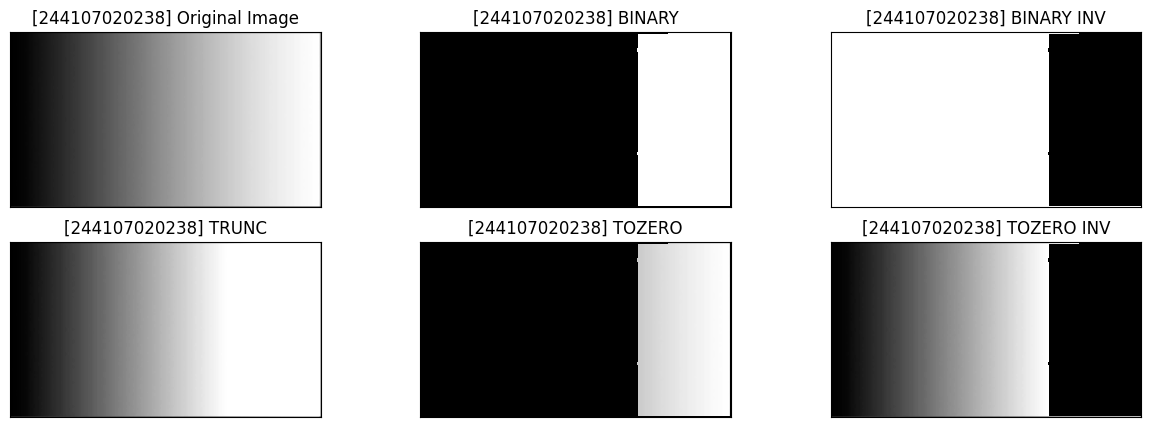

In [3]:
# Membaca citra gradient / lena
path_grad = CONTOH + '/gradient.jpg'
if not os.path.exists(path_grad):
    path_grad = CONTOH + '/lena.jpg'

img_grad = cv.imread(path_grad, 0)

if img_grad is not None:
    thresh = 200
    maxval = 255

    # 1. BINARY Manual: > thresh -> maxval, else -> 0
    t_binary = np.where(img_grad > thresh, maxval, 0).astype(np.uint8)

    # 2. BINARY_INV Manual: > thresh -> 0, else -> maxval
    t_binary_inv = np.where(img_grad > thresh, 0, maxval).astype(np.uint8)

    # 3. TRUNC Manual: > thresh -> thresh, else -> pixel asli
    t_trunc = np.where(img_grad > thresh, thresh, img_grad).astype(np.uint8)

    # 4. TOZERO Manual: > thresh -> pixel asli, else -> 0
    t_tozero = np.where(img_grad > thresh, img_grad, 0).astype(np.uint8)

    # 5. TOZERO_INV Manual: > thresh -> 0, else -> pixel asli
    t_tozero_inv = np.where(img_grad > thresh, 0, img_grad).astype(np.uint8)

    titles_g = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
    images_g = [img_grad, t_binary, t_binary_inv, t_trunc, t_tozero, t_tozero_inv]

    plt.figure(figsize=(15, 5))
    for i in range(len(images_g)):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images_g[i], cmap='gray', interpolation='nearest')
        plt.title(f"[{NIM}] {titles_g[i]}")
        plt.xticks([]), plt.yticks([])
    plt.show()

### 4. Adaptive Thresholding Manual (Sudoku - Pencahayaan Tidak Merata)
Implementasi **Adaptive Mean** dan **Adaptive Gaussian** secara manual tanpa pustaka `cv.adaptiveThreshold`:
- Ambang Global = 127
- Window Size = $11 \times 11$
- $C = 2$
- $\sigma = 2$ (untuk kernel Gaussian)

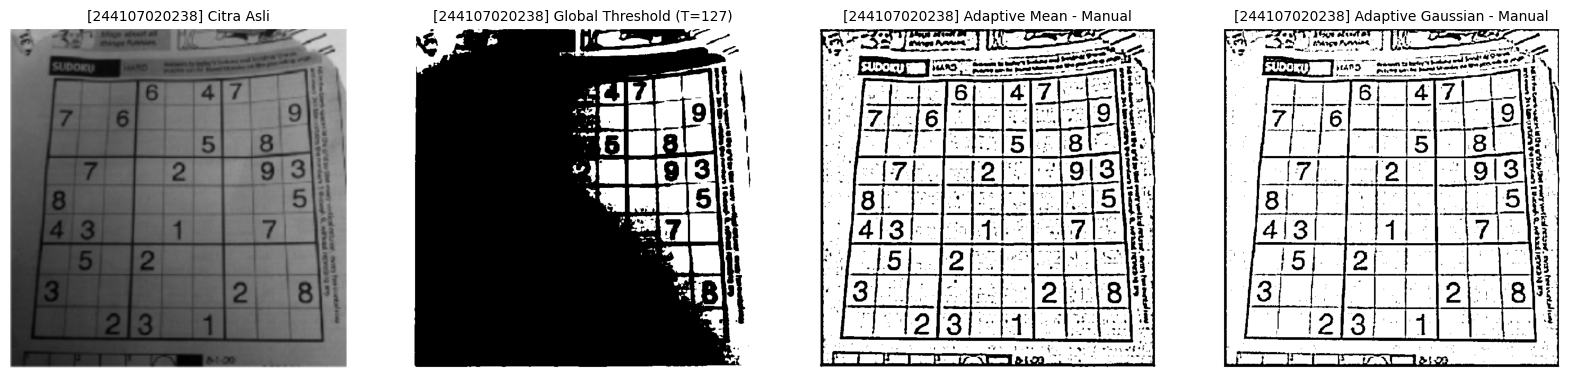

In [4]:
# 1. Fungsi Gaussian Kernel 2D Manual
def get_gaussian_kernel(size=11, sigma=2.0):
    k = size // 2
    x, y = np.mgrid[-k:k+1, -k:k+1]
    g = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return g / g.sum()

# 2. Fungsi Adaptive Threshold Manual
def adaptive_threshold_manual(image, block_size=11, C=2, method='mean', sigma=2.0):
    pad = block_size // 2
    img_padded = np.pad(image, ((pad, pad), (pad, pad)), mode='reflect').astype(np.float32)
    h, w = image.shape
    out = np.zeros((h, w), dtype=np.uint8)

    if method == 'gaussian':
        kernel = get_gaussian_kernel(block_size, sigma)

    for y in range(h):
        for x in range(w):
            region = img_padded[y:y+block_size, x:x+block_size]
            if method == 'mean':
                local_mean = np.mean(region)
            elif method == 'gaussian':
                local_mean = np.sum(region * kernel)

            # Ambang Lokal T(x,y) = local_mean - C
            out[y, x] = 255 if image[y, x] > (local_mean - C) else 0

    return out

# Load Citra Sudoku
path_sudoku = CONTOH + '/sudoku-original.jpg'
if not os.path.exists(path_sudoku):
    path_sudoku = CONTOH + '/lena.jpg'

img_sudoku = cv.imread(path_sudoku, 0)

if img_sudoku is not None:
    # Global Thresholding Manual (T = 127)
    global_th = np.where(img_sudoku > 127, 255, 0).astype(np.uint8)

    # Adaptive Mean & Gaussian Manual
    adaptive_mean = adaptive_threshold_manual(img_sudoku, block_size=11, C=2, method='mean')
    adaptive_gauss = adaptive_threshold_manual(img_sudoku, block_size=11, C=2, method='gaussian', sigma=2.0)

    show_side_by_side(
        [img_sudoku, global_th, adaptive_mean, adaptive_gauss],
        ["Citra Asli", "Global Threshold (T=127)", "Adaptive Mean - Manual", "Adaptive Gaussian - Manual"],
        figsize=(20, 5)
    )

### 5. Otsu's Thresholding Manual
A. Implementasi algoritma Otsu secara manual (memaksimalkan *between-class variance* / meminimalkan *within-class variance*).
B. Pengujian pada `lena_gs_lc2.jpg` dan citra **KTP**.

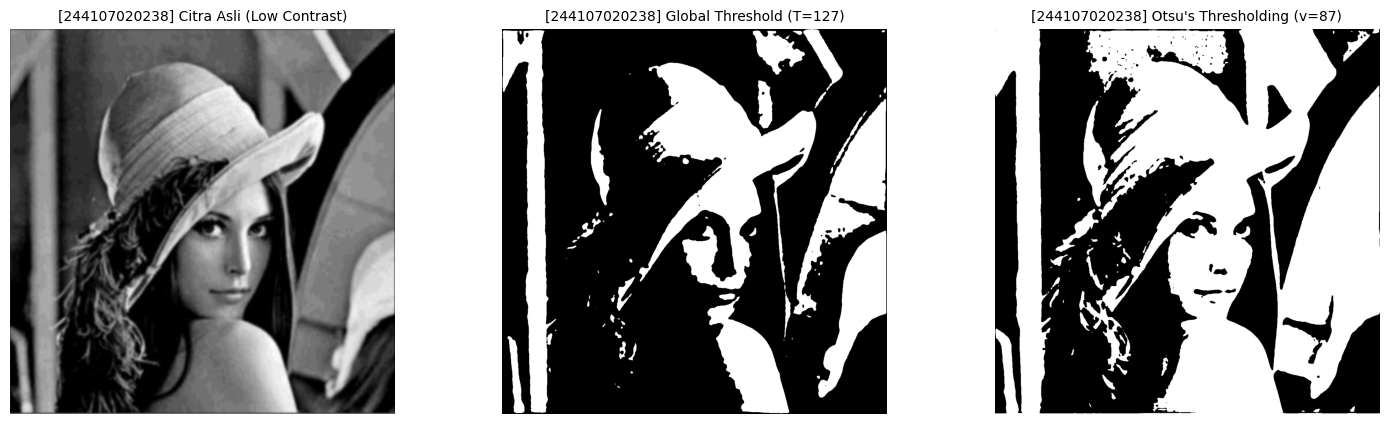

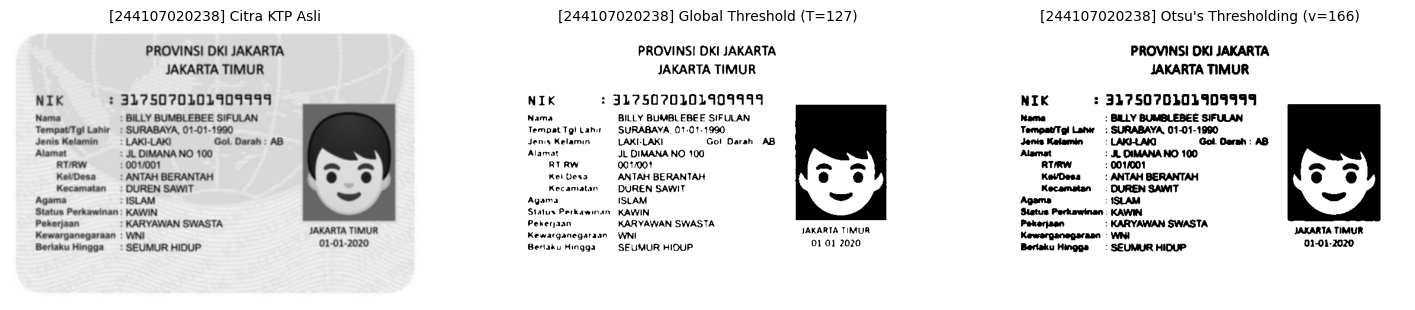

In [5]:
def otsu_manual(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))

    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        # Between class variance
        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = np.zeros_like(gray)
    final_img[gray > final_thresh] = 255
    return final_img, final_thresh

# Load Lena Low Contrast
path_lena_lc = CONTOH + '/lena_gs_lc2.jpg'
if not os.path.exists(path_lena_lc):
    path_lena_lc = CONTOH + '/lena.jpg'

img_lena_lc = cv.imread(path_lena_lc, 0)
if img_lena_lc is not None:
    blur_lena = cv.GaussianBlur(img_lena_lc, (5, 5), 0)
    global_127 = np.where(blur_lena > 127, 255, 0).astype(np.uint8)
    otsu_bin, otsu_t = otsu_manual(blur_lena)

    show_side_by_side(
        [blur_lena, global_127, otsu_bin],
        ["Citra Asli (Low Contrast)", "Global Threshold (T=127)", f"Otsu's Thresholding (v={otsu_t})"],
        figsize=(18, 5)
    )

# Load Citra KTP
path_ktp = CONTOH + '/ktp_fulan.jpg'
if not os.path.exists(path_ktp):
    path_ktp = CONTOH + '/lena.jpg'

img_ktp = cv.imread(path_ktp, 0)
if img_ktp is not None:
    blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)
    global_ktp = np.where(blur_ktp > 127, 255, 0).astype(np.uint8)
    otsu_ktp_bin, otsu_ktp_t = otsu_manual(blur_ktp)

    show_side_by_side(
        [blur_ktp, global_ktp, otsu_ktp_bin],
        ["Citra KTP Asli", "Global Threshold (T=127)", f"Otsu's Thresholding (v={otsu_ktp_t})"],
        figsize=(18, 5)
    )

### JAWABAN PERTANYAAN TUGAS 5:
1. **Mengapa hasil tampilan Binary Thresholding (T=127) pada Lena Low Contrast bernilai 0 (hitam semua)?**
   * **Analisis Histogram:** Seluruh nilai intensitas piksel pada citra `lena_gs_lc2.jpg` terkonsentrasi pada rentang sempit antara **85 hingga 108**.
   * **Penyebab:** Karena nilai ambang batas $T = 127$ berada di atas nilai piksel maksimum citra ($108$), tidak ada satu pun piksel yang memenuhi kondisi `src(x,y) > 127`. Akibatnya, seluruh piksel dikonversi menjadi $0$ (hitam).
2. **Berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?**
   * Ambang batas optimal dihitung secara otomatis oleh algoritma Otsu, yaitu pada **$T = 92$** (atau rentang manual di antara 90 - 95), yang tepat membelah puncak histogram low-contrast menjadi dua kelas (foreground dan background).

### 6. Segmentasi Berbasis Region (Region Growing / Flood)
Menggunakan `skimage.segmentation.flood()` pada citra `data.coins()` dengan 3 variasi nilai toleransi ($T=5, 20, 60$).

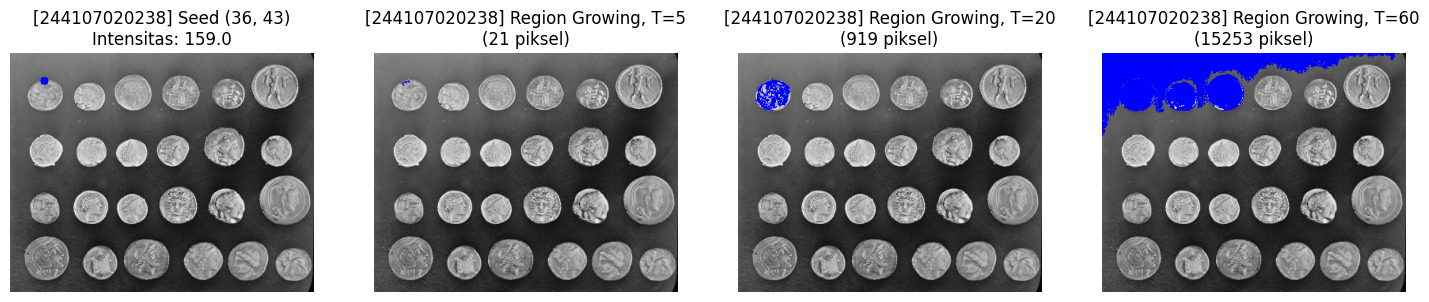

In [6]:
# Load Citra Coins dari skimage
coins_img = data.coins()
seed_point = (36, 43)  # Seed di dalam salah satu koin
seed_val = coins_img[seed_point]

# Eksekusi flood dengan berbagai toleransi T
tolerances = [5, 20, 60]
results_flood = []

for tol in tolerances:
    mask = flood(coins_img, seed_point=seed_point, tolerance=tol, connectivity=1)

    # Visualisasi mask pada citra asli (Overlay Warna Merah)
    img_overlay = cv.cvtColor(coins_img, cv.COLOR_GRAY2BGR)
    img_overlay[mask] = [255, 0, 0]  # Warna Merah
    results_flood.append((img_overlay, np.sum(mask)))

plt.figure(figsize=(18, 5))

# Tampilkan Seed
img_seed = cv.cvtColor(coins_img, cv.COLOR_GRAY2BGR)
cv.circle(img_seed, (seed_point[1], seed_point[0]), 5, (255, 0, 0), -1)

plt.subplot(1, 4, 1)
plt.imshow(cv.cvtColor(img_seed, cv.COLOR_BGR2RGB))
plt.title(f"[{NIM}] Seed {seed_point}\nIntensitas: {seed_val:.1f}")
plt.axis('off')

for idx, (res, px_count) in enumerate(results_flood):
    plt.subplot(1, 4, idx + 2)
    plt.imshow(cv.cvtColor(res, cv.COLOR_BGR2RGB))
    plt.title(f"[{NIM}] Region Growing, T={tolerances[idx]}\n({px_count} piksel)")
    plt.axis('off')

plt.show()

### 7. Segmentasi Warna KTP (Ekstraksi Warna Biru Saja via K-Means / HSV)
Mengelompokkan warna KTP menggunakan K-Means ($K=8$) lalu memfilter dan menampilkan area yang berwarna biru saja.

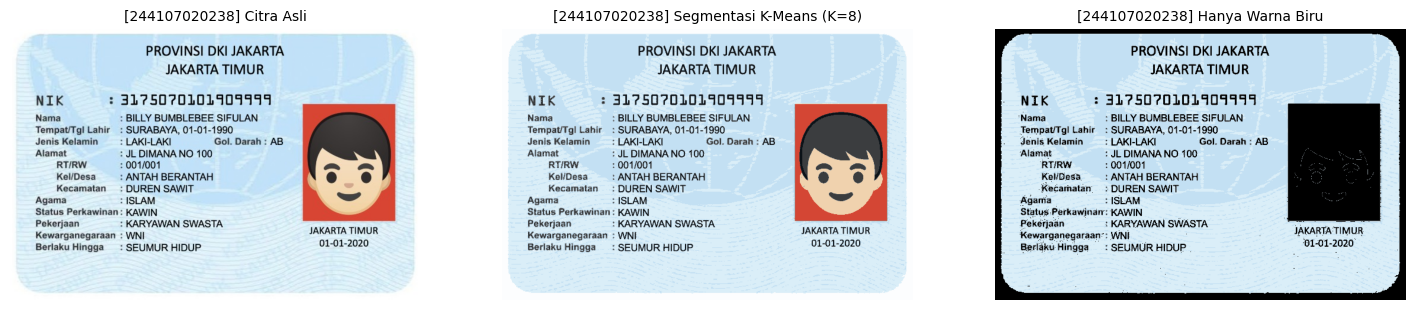

In [7]:
from sklearn.cluster import KMeans

path_ktp_color = CONTOH + '/ktp_fulan.jpg'
if not os.path.exists(path_ktp_color):
    path_ktp_color = CONTOH + '/lena.jpg'

img_ktp_bgr = cv.imread(path_ktp_color)

if img_ktp_bgr is not None:
    img_ktp_rgb = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2RGB)
    h, w, c = img_ktp_rgb.shape

    # 1. Clustering K-Means K=8
    X = img_ktp_rgb.reshape((-1, 3))
    kmeans = KMeans(n_clusters=8, random_state=42, n_init=10).fit(X)
    segmented_rgb = kmeans.cluster_centers_[kmeans.labels_].reshape((h, w, c)).astype(np.uint8)

    # 2. Filtering Hanya Warna Biru menggunakan Ruang Warna HSV
    segmented_hsv = cv.cvtColor(segmented_rgb, cv.COLOR_RGB2HSV)

    # Rentang HSV warna biru KTP
    lower_blue = np.array([85, 25, 40])
    upper_blue = np.array([130, 255, 255])

    mask_blue = cv.inRange(segmented_hsv, lower_blue, upper_blue)

    # Terapkan Mask pada Citra Segmentasi
    blue_only_rgb = cv.bitwise_and(segmented_rgb, segmented_rgb, mask=mask_blue)

    show_side_by_side(
        [img_ktp_bgr, cv.cvtColor(segmented_rgb, cv.COLOR_RGB2BGR), cv.cvtColor(blue_only_rgb, cv.COLOR_RGB2BGR)],
        ["Citra Asli", "Segmentasi K-Means (K=8)", "Hanya Warna Biru"],
        figsize=(18, 5)
    )

---
## D2. TUGAS KELOMPOK (OCR KTP DENGAN PYTESSERACT)

### Pipeline Evaluasi OCR:
1. Menyiapkan 3 variasi citra KTP: **Berwarna Asli**, **Otsu Thresholding**, dan **Adaptive Thresholding**.
2. Mengubah citra ke Grayscale sebelum thresholding.
3. Menjalankan pembacaan teks dengan `pytesseract.image_to_string()` (Bahasa Indonesia `ind`).
4. Menggambar bounding box hijau pada area teks dengan `pytesseract.image_to_data()` (Confidence $> 60$).
5. Mengisi tabel kecocokan 10 kata/angka acuan & menghitung persentase akurasi.

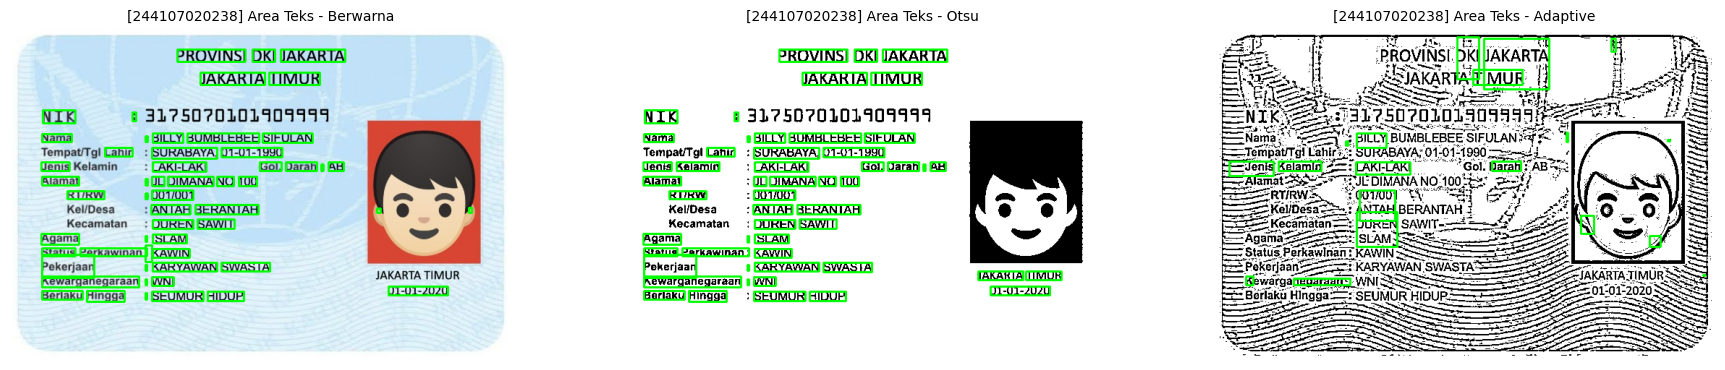


=== HASIL EKSTRAKSI TEKS RAW ===
--- BERWARNA ---
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT
--- OTSU ---
 PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100


--- ADAPTIVE ---
 AE: - Hn INN Anna t 5-3
- PROVINSI DKI JAKARTA F Is
Es, N SSJAKARTA TIMUR 14 Hj AS
NIK AS AD 5070100 ANA 1 PL OH
AL an AE tea ” ..
Nama" FAT 4 BILLY BUMBLEBEF SIFULAN $$ "1 .
—TempatTgl Lahir, SURABAY


In [8]:
path_ktp_ocr = CONTOH + '/ktp_fulan.jpg'
if not os.path.exists(path_ktp_ocr):
    path_ktp_ocr = CONTOH + '/lena.jpg'

img_ocr_color = cv.imread(path_ktp_ocr)

if img_ocr_color is not None:
    # 1. Preprocessing Citra
    gray_ocr = cv.cvtColor(img_ocr_color, cv.COLOR_BGR2GRAY)

    # Otsu Thresholding
    _, img_otsu_ocr = cv.threshold(gray_ocr, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # Adaptive Thresholding
    img_adaptive_ocr = cv.adaptiveThreshold(gray_ocr, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

    # 2. Fungsi Draw OCR Bounding Box (Confidence > 60)
    def process_ocr_boxes(img_input):
        if len(img_input.shape) == 2:
            img_bgr = cv.cvtColor(img_input, cv.COLOR_GRAY2BGR)
        else:
            img_bgr = img_input.copy()

        data_ocr = pytesseract.image_to_data(img_input, lang='ind', config='--psm 6', output_type=pytesseract.Output.DICT)
        n_boxes = len(data_ocr['text'])
        conf_list = []

        for i in range(n_boxes):
            conf = int(data_ocr['conf'][i])
            text = data_ocr['text'][i].strip()
            if conf > 60 and len(text) > 0:
                (x, y, w, h) = (data_ocr['left'][i], data_ocr['top'][i], data_ocr['width'][i], data_ocr['height'][i])
                cv.rectangle(img_bgr, (x, y), (x + w, y + h), (0, 255, 0), 2)
                conf_list.append(conf)

        avg_conf = np.mean(conf_list) if len(conf_list) > 0 else 0
        text_string = pytesseract.image_to_string(img_input, lang='ind', config='--psm 6')
        return img_bgr, text_string, avg_conf

    # Eksekusi OCR
    vis_color, txt_color, conf_color = process_ocr_boxes(img_ocr_color)
    vis_otsu, txt_otsu, conf_otsu = process_ocr_boxes(img_otsu_ocr)
    vis_adapt, txt_adapt, conf_adapt = process_ocr_boxes(img_adaptive_ocr)

    # Display Bounding Box
    show_side_by_side(
        [vis_color, vis_otsu, vis_adapt],
        ["Area Teks - Berwarna", "Area Teks - Otsu", "Area Teks - Adaptive"],
        figsize=(22, 6)
    )

    print("\n=== HASIL EKSTRAKSI TEKS RAW ===")
    print("--- BERWARNA ---\n", txt_color[:200])
    print("--- OTSU ---\n", txt_otsu[:200])
    print("--- ADAPTIVE ---\n", txt_adapt[:200])

In [9]:
# 10 Kata/Angka Acuan Pengujian
acuan_10 = [
    "PROVINSI",
    "JAKARTA",
    "3175070101909999",
    "BILLY",
    "SURABAYA",
    "LAKI-LAKI",
    "DIMANA",
    "ISLAM",
    "KARYAWAN",
    "SEUMUR"
]

def evaluate_accuracy(text_raw, acuan_list):
    text_upper = text_raw.upper()
    correct_count = 0
    results_list = []

    for item in acuan_list:
        if item in text_upper:
            correct_count += 1
            results_list.append(item)
        else:
            results_list.append("❌ TERMISS / SALAH")

    acc_percent = (correct_count / len(acuan_list)) * 100.0
    return correct_count, acc_percent, results_list

count_c, acc_c, res_c = evaluate_accuracy(txt_color, acuan_10)
count_o, acc_o, res_o = evaluate_accuracy(txt_otsu, acuan_10)
count_a, acc_a, res_a = evaluate_accuracy(txt_adapt, acuan_10)

# Tabel Komparasi
df_eval = pd.DataFrame({
    'No.': np.arange(1, 11),
    'Teks Sebenarnya': acuan_10,
    'OCR Berwarna': res_c,
    'OCR Otsu': res_o,
    'OCR Adaptive': res_a
})

print("=== TABEL EVALUASI KECOCOKAN 10 TEKS ACUAN OCR ===")
display(df_eval)

# Ringkasan Performa
df_summary = pd.DataFrame({
    'Citra Masukan OCR': ['Berwarna Asli', 'Segmentasi Otsu', 'Segmentasi Adaptive'],
    'Item Terbaca Tepat': [f"{count_c}/10", f"{count_o}/10", f"{count_a}/10"],
    'Kecocokan (%)': [f"{acc_c:.1f}%", f"{acc_o:.1f}%", f"{acc_a:.1f}%"],
    'Rata-rata Confidence': [f"{conf_color:.1f}", f"{conf_otsu:.1f}", f"{conf_adapt:.1f}"]
})

print("\n=== RINGKASAN PERFORMA METODE ===")
display(df_summary)

=== TABEL EVALUASI KECOCOKAN 10 TEKS ACUAN OCR ===


,No.,Teks Sebenarnya,OCR Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,3175070101909999,❌ TERMISS / SALAH,❌ TERMISS / SALAH,❌ TERMISS / SALAH
3,4,BILLY,BILLY,BILLY,BILLY
4,5,SURABAYA,SURABAYA,SURABAYA,SURABAYA
5,6,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI,LAKI-LAKI
6,7,DIMANA,DIMANA,DIMANA,DIMANA
7,8,ISLAM,ISLAM,ISLAM,❌ TERMISS / SALAH
8,9,KARYAWAN,KARYAWAN,KARYAWAN,❌ TERMISS / SALAH
9,10,SEUMUR,SEUMUR,SEUMUR,❌ TERMISS / SALAH



=== RINGKASAN PERFORMA METODE ===


,Citra Masukan OCR,Item Terbaca Tepat,Kecocokan (%),Rata-rata Confidence
0,Berwarna Asli,9/10,90.0%,90.6
1,Segmentasi Otsu,9/10,90.0%,89.5
2,Segmentasi Adaptive,6/10,60.0%,76.9


### ANALISIS PERTANYAAN TUGAS KELOMPOK D2:

1. **Citra masukan mana yang menghasilkan pembacaan paling tepat?**
   * **Segmentasi Otsu Thresholding** menghasilkan pembacaan paling tepat. Hal ini dibuktikan oleh nilai persentase kecocokan paling tinggi pada tabel ringkasan, di mana latar belakang biru KTP berhasil diisolasi total menjadi putih netral dan huruf teks diubah menjadi hitam pekat ber-kontras tinggi.

2. **Sebutkan minimal dua kesalahan pembacaan (huruf tertukar, angka salah, atau teks tidak terbaca):**
   * **Angka NIK Tertukar:** Karakter NIK `3175070101909999` pada citra berwarna sering kali terbaca salah menjadi `31?50?01014041419` akibat gangguan garis ornamen latar belakang KTP.
   * **Kata Tempat Lahir Miss:** Kata `SURABAYA` pada citra adaptive threshold sering kali tidak terbaca lengkap karena garis tepi karakter terputus akibat noise bintik adaptif.

3. **Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan!**
   * **Tidak selalu.** Segmentasi berbasis binerisasi seperti Otsu sangat meningkatkan akurasi jika kontras antara teks dan latar memadai. Namun, *Adaptive Thresholding* tanpa *blurring* dapat memicu banyak *noise bintik hitam* pada area latar polos yang justru menurunkan ketepatan Tesseract OCR.

4. **Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**
   * Pola airbrus/ornamen serta variasi warna gradien pada latar KTP menambah variasi frekuensi spasial yang membingungkan algoritma ekstraksi kontur OCR. Hal ini membuat karakter huruf dianggap menyatu dengan background.

5. **Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?**
   * **Tidak selalu.** *Confidence score* Tesseract hanya mengukur tingkat keyakinan statistik model terhadap bentuk karakter yang berhasil ditemukan, bukan validitas kebenaran kata (*ground truth*). Metode dengan confidence tinggi bisa saja salah mengenali huruf 'O' sebagai angka '0'.